# Final Essay – Machine Learning
## Question 1: FNN with Backpropagation for Regression (Part 1a, 1b)

Run the cells from top to bottom (**Runtime → Run all**). Only NumPy, Pandas, Matplotlib and scikit-learn are used; the network and backpropagation are implemented from scratch.

**Part 1a (theory)** is in the report. Notation: `z^l = W^l a^(l-1) + b^l`, `a^l = f(z^l)`, loss `J = (1/2m) Σ ||ŷ − y||²` (+ `(λ/2m) Σ ||W||²` for L2), and

- BP1: `δ^L = (a^L − y) ⊙ f'(z^L)` (linear output layer: `f' = 1`)
- BP2: `δ^l = ((W^(l+1))ᵀ δ^(l+1)) ⊙ f'(z^l)`
- BP3: `∂J/∂b^l = δ^l`
- BP4: `∂J/∂W^l = δ^l (a^(l-1))ᵀ`

## 1. Imports

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 2. FNN implementation from scratch (Part 1b)
Forward propagation, backpropagation (BP1–BP4), mini-batch Gradient Descent, evaluation metrics and gradient checking. `fit()` already supports `l2_lambda`, `early_stopping`, `patience` and `min_delta` for Parts 1c–1e.

In [2]:
# ----------------------------- Activation functions ------------------------
def _relu(z):
    return np.maximum(0.0, z)


def _relu_d(z, a):
    return (z > 0).astype(z.dtype)


def _tanh(z):
    return np.tanh(z)


def _tanh_d(z, a):
    return 1.0 - a ** 2


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def _sigmoid_d(z, a):
    return a * (1.0 - a)


ACTIVATIONS = {
    "relu": (_relu, _relu_d),
    "tanh": (_tanh, _tanh_d),
    "sigmoid": (_sigmoid, _sigmoid_d),
}


# ------------------------------ Evaluation metrics -------------------------
def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def rmse(y_true, y_pred):
    return float(np.sqrt(mse(y_true, y_pred)))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


class FNN:
    """FNN with several hidden layers and a linear output layer (regression).

    layer_sizes: e.g. [8, 64, 32, 1] -> 2 hidden layers.
    """

    def __init__(self, layer_sizes, activation="relu", seed=0):
        assert len(layer_sizes) >= 4, "At least 2 hidden layers are required by the assignment."
        self.sizes = list(layer_sizes)
        self.act, self.act_d = ACTIVATIONS[activation]
        self.activation = activation
        self.rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(self.sizes[:-1], self.sizes[1:]):
            if activation == "relu":          # He initialization
                std = np.sqrt(2.0 / n_in)
            else:                              # Xavier initialization
                std = np.sqrt(1.0 / n_in)
            self.W.append(self.rng.normal(0.0, std, size=(n_in, n_out)))
            self.b.append(np.zeros((1, n_out)))
        self.train_loss_history = []
        self.val_loss_history = []

    # ------------------------------ Forward -------------------------------
    def forward(self, X):
        """Return the lists of z and a for every layer (A[0] = X)."""
        A, Z = [X], []
        L = len(self.W)
        for l in range(L):
            z = A[-1] @ self.W[l] + self.b[l]
            Z.append(z)
            A.append(z if l == L - 1 else self.act(z))   # linear output layer
        return Z, A

    def predict(self, X):
        return self.forward(X)[1][-1]

    # ------------------------------- Loss ---------------------------------
    def loss(self, X, y, l2_lambda=0.0):
        """J = (1/2m) sum ||yhat - y||^2 + (lam/2m) sum ||W||^2."""
        m = X.shape[0]
        yhat = self.predict(X)
        J = np.sum((yhat - y) ** 2) / (2.0 * m)
        if l2_lambda > 0:
            J += l2_lambda / (2.0 * m) * sum(np.sum(W ** 2) for W in self.W)
        return float(J)

    # ------------------------------ Backward ------------------------------
    def backward(self, X, y, l2_lambda=0.0):
        """Backpropagation via the Chain Rule (BP1-BP4). Returns (dW, db)."""
        m = X.shape[0]
        Z, A = self.forward(X)
        L = len(self.W)
        dW, db = [None] * L, [None] * L
        delta = (A[-1] - y)                       # BP1 (f' = 1 at the output layer)
        for l in range(L - 1, -1, -1):
            dW[l] = A[l].T @ delta / m            # BP4
            db[l] = delta.sum(axis=0, keepdims=True) / m   # BP3
            if l2_lambda > 0:                     # L2 hook: add (lam/m) W
                dW[l] = dW[l] + (l2_lambda / m) * self.W[l]
            if l > 0:                             # BP2
                delta = (delta @ self.W[l].T) * self.act_d(Z[l - 1], A[l])
        return dW, db

    # ----------------------------- Weights --------------------------------
    def get_weights(self):
        return [W.copy() for W in self.W], [b.copy() for b in self.b]

    def set_weights(self, weights):
        Ws, bs = weights
        self.W = [W.copy() for W in Ws]
        self.b = [b.copy() for b in bs]

    # ------------------------------- Train --------------------------------
    def fit(self, X, y, X_val=None, y_val=None, epochs=500, lr=0.01,
            batch_size=32, l2_lambda=0.0, early_stopping=False,
            patience=20, min_delta=0.0, verbose=0, shuffle_seed=0):
        """Mini-batch Gradient Descent.

        The stored loss history is the pure data MSE (1/2m)sum||yhat-y||^2 (no L2 term),
        so configurations with/without L2 are compared fairly.
        Early stopping: monitor the validation loss, stop when it has not improved by
        at least `min_delta` for `patience` epochs, and restore the best weights.
        """
        rng = np.random.default_rng(shuffle_seed)
        m = X.shape[0]
        self.train_loss_history, self.val_loss_history = [], []
        best, best_w, best_epoch, wait = np.inf, None, 0, 0
        self.stopped_epoch = epochs
        for ep in range(1, epochs + 1):
            idx = rng.permutation(m)
            for s in range(0, m, batch_size):
                bi = idx[s:s + batch_size]
                dW, db = self._batch_grad(X[bi], y[bi], l2_lambda, m)
                for l in range(len(self.W)):
                    self.W[l] -= lr * dW[l]
                    self.b[l] -= lr * db[l]
            self.train_loss_history.append(self.loss(X, y))
            if X_val is not None:
                vl = self.loss(X_val, y_val)
                self.val_loss_history.append(vl)
                if early_stopping:
                    if vl < best - min_delta:
                        best, best_w, best_epoch, wait = vl, self.get_weights(), ep, 0
                    else:
                        wait += 1
                        if wait >= patience:
                            self.stopped_epoch = ep
                            break
            if verbose and ep % verbose == 0:
                v = self.val_loss_history[-1] if self.val_loss_history else float("nan")
                print(f"epoch {ep:4d}  train {self.train_loss_history[-1]:.5f}  val {v:.5f}")
        if early_stopping and best_w is not None:
            self.set_weights(best_w)
            self.best_epoch = best_epoch
        return self

    def _batch_grad(self, Xb, yb, l2_lambda, m_total):
        """Mini-batch gradient. The L2 penalty is scaled by m_total (size of the whole
        training set), i.e. each step adds (lam/m_total) W, to match the full objective J."""
        dW, db = self.backward(Xb, yb, 0.0)
        if l2_lambda > 0:
            dW = [g + (l2_lambda / m_total) * W for g, W in zip(dW, self.W)]
        return dW, db

    # ------------------------------ Evaluation ----------------------------
    def evaluate(self, X, y, y_scaler=None):
        """Return a dict of MSE/RMSE/MAE. If y_scaler is given, convert back to the original scale."""
        yp = self.predict(X)
        if y_scaler is not None:
            yp, y = y_scaler.inverse_transform(yp), y_scaler.inverse_transform(y)
        return {"MSE": mse(y, yp), "RMSE": rmse(y, yp), "MAE": mae(y, yp)}


# --------------------------- Gradient checking ------------------------------
def gradient_check(net, X, y, l2_lambda=0.0, eps=1e-5, n_checks=40, seed=0):
    """Compare backprop gradients with central finite differences.
    Returns the largest relative error (float64)."""
    rng = np.random.default_rng(seed)
    dW, db = net.backward(X, y, l2_lambda)
    worst = 0.0
    params = [(net.W, dW, l) for l in range(len(net.W))] + \
             [(net.b, db, l) for l in range(len(net.b))]
    for _ in range(n_checks):
        plist, glist, l = params[rng.integers(len(params))]
        arr = plist[l]
        i, j = rng.integers(arr.shape[0]), rng.integers(arr.shape[1])
        old = arr[i, j]
        arr[i, j] = old + eps
        Jp = net.loss(X, y, l2_lambda)
        arr[i, j] = old - eps
        Jm = net.loss(X, y, l2_lambda)
        arr[i, j] = old
        num, ana = (Jp - Jm) / (2 * eps), glist[l][i, j]
        rel = abs(num - ana) / max(1e-8, abs(num) + abs(ana))
        worst = max(worst, rel)
    return worst

## 3. Load data and preprocess
Dataset: Concrete Compressive Strength (UCI), 8 features, target `strength` (MPa).

In [3]:
SEED = 42
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/concrete.csv"
df = pd.read_csv(URL)
print("Original shape:", df.shape, "| missing:", int(df.isna().sum().sum()),
      "| duplicates:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)   # avoid duplicate samples leaking between train and test
print("After dropping duplicates:", df.shape)
df.describe().T

Original shape: (1030, 9) | missing: 0 | duplicates: 25
After dropping duplicates: (1005, 9)


,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.631343,104.344261,102.00,190.70,265.0,349.00,540.0
slag,1005.0,72.043483,86.170807,0.00,0.00,20.0,142.50,359.4
ash,1005.0,55.536318,64.207969,0.00,0.00,0.0,118.30,200.1
water,1005.0,182.075323,21.339334,121.80,166.60,185.7,192.90,247.0
superplastic,1005.0,6.033234,5.919967,0.00,0.00,6.1,10.00,32.2
coarseagg,1005.0,974.376816,77.579667,801.00,932.00,968.0,1031.00,1145.0
fineagg,1005.0,772.688259,80.340435,594.00,724.30,780.0,822.20,992.6
age,1005.0,45.856716,63.734692,1.00,7.00,28.0,56.00,365.0
strength,1005.0,35.250378,16.284815,2.33,23.52,33.8,44.87,82.6


### Train / Validation / Test split (70/15/15) and standardization
The scalers are fitted on the training set only to avoid data leakage.

In [4]:
X = df.drop(columns="strength").values
y = df[["strength"]].values

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)
print("Train/Val/Test:", len(X_tr), len(X_va), len(X_te))

xs, ys = StandardScaler().fit(X_tr), StandardScaler().fit(y_tr)
X_tr, X_va, X_te = xs.transform(X_tr), xs.transform(X_va), xs.transform(X_te)
y_tr, y_va, y_te = ys.transform(y_tr), ys.transform(y_va), ys.transform(y_te)

Train/Val/Test: 703 151 151


## 4. Gradient checking
Compares the backpropagation gradients with numerical derivatives (central differences), with and without L2. Errors below 1e-6 mean the gradients are correct.

In [5]:
chk = {}
for act in ["tanh", "sigmoid", "relu"]:
    net = FNN([8, 16, 8, 1], activation=act, seed=1)
    chk[act] = {"no_L2": gradient_check(net, X_tr[:64], y_tr[:64]),
                "L2=0.5": gradient_check(net, X_tr[:64], y_tr[:64], l2_lambda=0.5)}
print("Gradient check (max relative error):")
for k, v in chk.items():
    print(f"  {k:8s} no_L2 = {v['no_L2']:.2e} | L2=0.5 = {v['L2=0.5']:.2e}")

Gradient check (max relative error):
  tanh     no_L2 = 5.82e-10 | L2=0.5 = 5.82e-10
  sigmoid  no_L2 = 2.92e-09 | L2=0.5 = 4.38e-09
  relu     no_L2 = 2.36e-10 | L2=0.5 = 3.40e-10


## 5. Baseline model: 8-64-32-1, ReLU, no regularization

In [6]:
net = FNN([8, 64, 32, 1], activation="relu", seed=0)
net.fit(X_tr, y_tr, X_va, y_va, epochs=600, lr=0.01, batch_size=32, verbose=100)

epoch  100  train 0.06154  val 0.12854
epoch  200  train 0.04175  val 0.10928
epoch  300  train 0.03273  val 0.10070
epoch  400  train 0.02679  val 0.09270
epoch  500  train 0.02347  val 0.08950
epoch  600  train 0.02095  val 0.08574


### Evaluation (MSE, RMSE, MAE on the original scale, MPa)

In [7]:
res = {s: net.evaluate(X_, y_, ys) for s, X_, y_ in
       [("train", X_tr, y_tr), ("val", X_va, y_va), ("test", X_te, y_te)]}
pd.DataFrame(res).T.round(4)

,MSE,RMSE,MAE
train,10.6898,3.2695,2.3857
val,43.7459,6.6141,4.2464
test,35.4004,5.9498,4.2631


### Training and validation loss

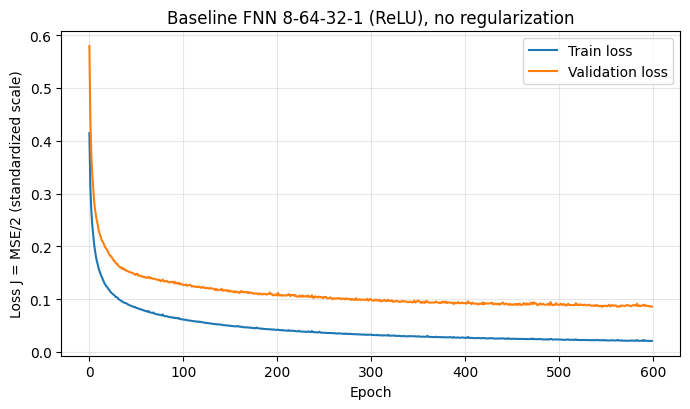

In [8]:
plt.figure(figsize=(7, 4.2))
plt.plot(net.train_loss_history, label="Train loss")
plt.plot(net.val_loss_history, label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss J = MSE/2 (standardized scale)")
plt.title("Baseline FNN 8-64-32-1 (ReLU), no regularization")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("baseline_loss.png", dpi=200)
plt.show()